# Data exploration

In [2]:
from pathlib import Path

data_dir = Path("../data/fashion_mnist")

for file_path in sorted(data_dir.iterdir()):
    print(
        f"File: {file_path.name} | "
        f"Size: {file_path.stat().st_size / (1024 * 1024):.2f} MB"
    )

File: t10k-images-idx3-ubyte.gz | Size: 4.22 MB
File: t10k-labels-idx1-ubyte.gz | Size: 0.00 MB
File: train-images-idx3-ubyte.gz | Size: 25.20 MB
File: train-labels-idx1-ubyte.gz | Size: 0.03 MB


In [3]:
import gzip
from pathlib import Path

data_dir = Path("../data/fashion_mnist")

image_file = data_dir / "train-images-idx3-ubyte.gz"
label_file = data_dir / "train-labels-idx1-ubyte.gz"

with gzip.open(image_file, "rb") as file:
    image_header = file.read(16)

with gzip.open(label_file, "rb") as file:
    label_header = file.read(8)

print("Image header bytes:", image_header)
print("Image header length:", len(image_header))

print("\nLabel header bytes:", label_header)
print("Label header length:", len(label_header))

Image header bytes: b'\x00\x00\x08\x03\x00\x00\xea`\x00\x00\x00\x1c\x00\x00\x00\x1c'
Image header length: 16

Label header bytes: b'\x00\x00\x08\x01\x00\x00\xea`'
Label header length: 8


In [4]:
import gzip
import struct
from pathlib import Path

data_dir = Path("../data/fashion_mnist")

image_file = data_dir / "train-images-idx3-ubyte.gz"
label_file = data_dir / "train-labels-idx1-ubyte.gz"

# Decode the image header
with gzip.open(image_file, "rb") as file:
    image_header = file.read(16)

magic_number, num_images, rows, columns = struct.unpack(
    ">IIII", image_header
)

# Decode the label header
with gzip.open(label_file, "rb") as file:
    label_header = file.read(8)

label_magic_number, num_labels = struct.unpack(
    ">II", label_header
)

print("IMAGE FILE")
print("Magic number:", magic_number)
print("Number of images:", num_images)
print("Rows per image:", rows)
print("Columns per image:", columns)

print("\nLABEL FILE")
print("Magic number:", label_magic_number)
print("Number of labels:", num_labels)

print("\nDo image and label counts match?", num_images == num_labels)

IMAGE FILE
Magic number: 2051
Number of images: 60000
Rows per image: 28
Columns per image: 28

LABEL FILE
Magic number: 2049
Number of labels: 60000

Do image and label counts match? True


In [5]:
#Load and Decode Fashion-MNIST Files
import gzip
import struct
from pathlib import Path

import numpy as np

data_dir = Path("../data/fashion_mnist")


def load_images(file_path):
    """Load images from a compressed Fashion-MNIST IDX file."""

    with gzip.open(file_path, "rb") as file:
        # Read the 16-byte image header.
        header = file.read(16)

        magic_number, num_images, rows, columns = struct.unpack(
            ">IIII", header
        )

        # Validate the file format.
        if magic_number != 2051:
            raise ValueError(
                f"Expected image magic number 2051, got {magic_number}"
            )

        # Read all remaining bytes containing the pixel values.
        image_data = file.read()

    # Convert bytes into an array of unsigned 8-bit integers.
    images = np.frombuffer(image_data, dtype=np.uint8)

    # Arrange pixels into individual images.
    images = images.reshape(num_images, rows, columns)

    return images


def load_labels(file_path):
    """Load labels from a compressed Fashion-MNIST IDX file."""

    with gzip.open(file_path, "rb") as file:
        # Read the 8-byte label header.
        header = file.read(8)

        magic_number, num_labels = struct.unpack(">II", header)

        # Validate the file format.
        if magic_number != 2049:
            raise ValueError(
                f"Expected label magic number 2049, got {magic_number}"
            )

        # Read the remaining bytes containing the labels.
        label_data = file.read()

    labels = np.frombuffer(label_data, dtype=np.uint8)

    # Verify the number of labels matches the header.
    if len(labels) != num_labels:
        raise ValueError(
            f"Expected {num_labels} labels, found {len(labels)}"
        )

    return labels

### Load Training and Test Data

In [6]:
# Load training data
X_train = load_images(data_dir / "train-images-idx3-ubyte.gz")
y_train = load_labels(data_dir / "train-labels-idx1-ubyte.gz")

# Load test data
X_test = load_images(data_dir / "t10k-images-idx3-ubyte.gz")
y_test = load_labels(data_dir / "t10k-labels-idx1-ubyte.gz")

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


### Inspect Data Types and Pixel Values


In [7]:
print("Training images data type:", X_train.dtype)
print("Training labels data type:", y_train.dtype)

print("\nMinimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

print("\nUnique training labels:", sorted(set(y_train)))

Training images data type: uint8
Training labels data type: uint8

Minimum pixel value: 0
Maximum pixel value: 255

Unique training labels: [np.uint8(0), np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(8), np.uint8(9)]


### Visualize Sample Fashion-MNIST Images

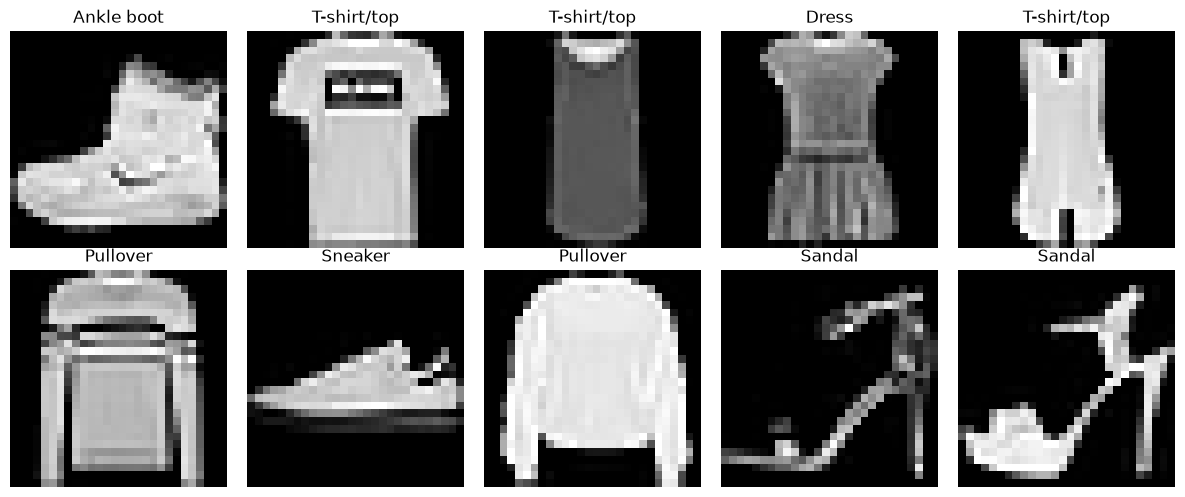

In [8]:
import matplotlib.pyplot as plt

# Define the clothing category names
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Display the first 10 training images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
#### Analyze Clothing Category Distribution

In [10]:
from collections import Counter

# Count images belonging to each category
label_counts = Counter(y_train)

for label, count in sorted(label_counts.items()):
    print(f"{class_names[label]}: {count}")

T-shirt/top: 6000
Trouser: 6000
Pullover: 6000
Dress: 6000
Coat: 6000
Sandal: 6000
Shirt: 6000
Sneaker: 6000
Bag: 6000
Ankle boot: 6000


In [11]:
### Visualize Clothing Category Distribution

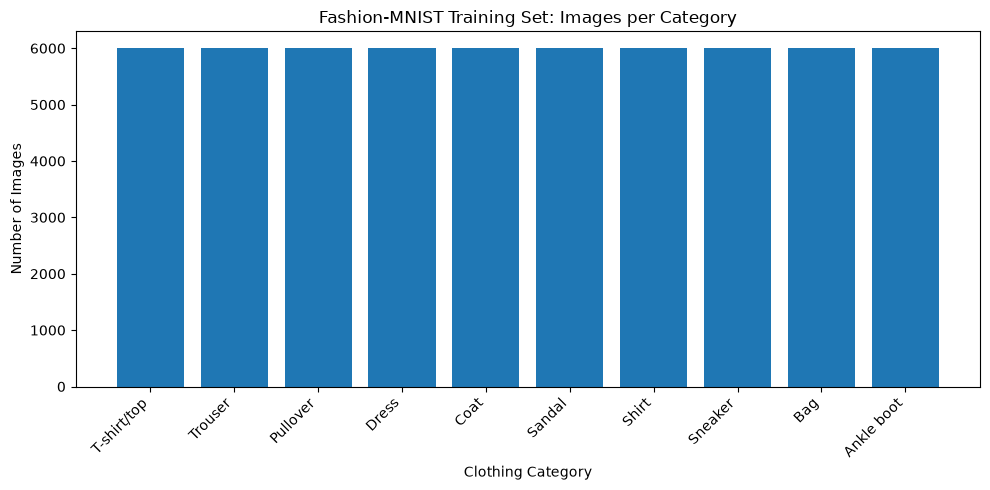

In [12]:
import matplotlib.pyplot as plt

# Prepare category names and image counts
categories = [class_names[label] for label in sorted(label_counts)]
counts = [label_counts[label] for label in sorted(label_counts)]

# Create a bar chart
plt.figure(figsize=(10, 5))
plt.bar(categories, counts)
plt.title("Fashion-MNIST Training Set: Images per Category")
plt.xlabel("Clothing Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Dataset Exploration Summary

- **Dataset:** Fashion-MNIST
- **Total images:** 70,000
- **Training set:** 60,000 images
- **Test set:** 10,000 images
- **Image dimensions:** 28 × 28 pixels
- **Image format:** Grayscale
- **Pixel values:** 0–255 (`uint8`)
- **Categories:** 10 clothing classes
- **Training distribution:** 6,000 images per category

### Key Observations
- All four dataset files loaded successfully.
- Sample images and their labels were visualized.
- The training dataset contains an equal number of images per category.
- The test set is reserved for evaluating model performance on unseen images.
